# pyATM: the ATM library from Python

This notebook walks through the functionality exercised by the ATM unit tests
(`TELCAL/TelCalResults/Libraries/ATM/test`, ported to `tests/test_atm_*.py`):

1. Physical quantities (`Length`, `Pressure`, `Temperature`, `Frequency`, ...) — *LengthTest*
2. Atmospheric profile (`AtmProfile`) — *AtmProfileTest*, *atmPres560test*
3. Spectral grids, single and double sideband (`SpectralGrid`) — *SpectralGridTest*
4. Absorption coefficients and opacities (`RefractiveIndexProfile`) — *RefractiveIndexProfileTest*
5. Sky brightness, transmission and path lengths (`SkyStatus`) — *SkyStatusTest*, *AtmBasicTest*, *atm651*
6. Water vapour retrieval from a water vapour radiometer (`WaterVaporRadiometer`, `WVRMeasurement`) — *AbInitioTest*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyatm
from pyatm import (Angle, AtmProfile, DSB, Frequency, Humidity, LSB, Length, Percent, Pressure,
                   RefractiveIndexProfile, SkyStatus, SpectralGrid, Temperature, WVRMeasurement,
                   WaterVaporRadiometer)

print("pyatm", pyatm.__version__, "| ATM", pyatm.ATM_VERSION, "| C++ namespace", pyatm.CXX_NAMESPACE)

pyatm 1.0.0 | ATM 1.0.0 | C++ namespace telcal::atm


## 1. Physical quantities

Every quantity stores its value in SI units; `get(unit)` converts on output.

In [2]:
alt = Length(5000, "m")
print(alt, "->", alt.get("km"), "km,", alt.get("mm"), "mm")
p = Pressure(560, "mb")
print(p, "->", p.get("Pa"), "Pa,", p.get("hPa"), "hPa")
f = Frequency(183.31, "GHz")
print(f, "->", f.get("MHz"), "MHz,", float(f), "Hz (float() gives the SI value)")
print(Temperature(270, "K").get("K"), "K;", Angle(45, "deg").get("rad"), "rad;", Humidity(20, "%").get("%"), "%")

Length(5000, 'm') -> 5.0 km, 5000000.0 mm
Pressure(56000, 'Pa') -> 56000.0 Pa, 560.0 hPa
Frequency(1.8331e+11, 'Hz') -> 183310.0 MHz, 183310000000.0 Hz (float() gives the SI value)
270.0 K; 0.78539815 rad; 20.0 %


## 2. Atmospheric profile

`AtmProfile(altitude, P, T, lapse rate [K/km], humidity, water scale height, P step, P step factor, top, type)`
builds the layered atmosphere above the site. Type 1 is *tropical* (used for ALMA).

Atmosphere type : TROPICAL
Number of layers: 27
Zenith PWV      : 1.5764 mm


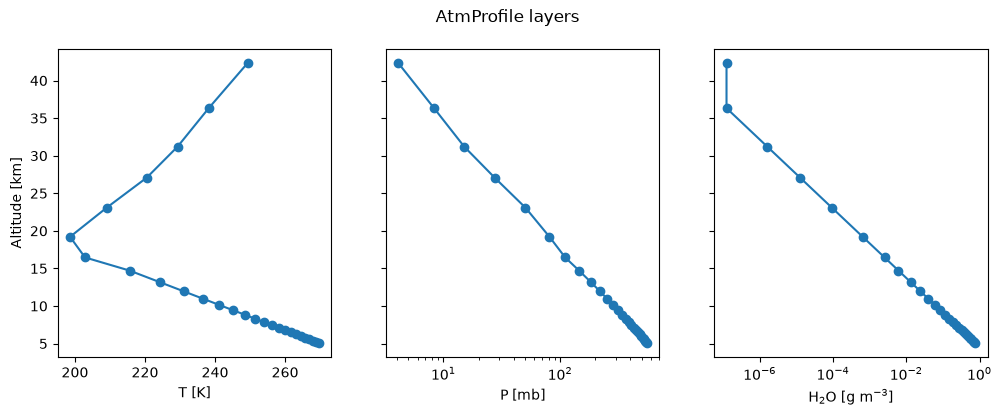

In [3]:
atmType = 1                      # 1 tropical, 2 mid-latitude summer, 3 mid-latitude winter, ...
profile = AtmProfile(Length(5000, "m"), Pressure(560, "mb"), Temperature(270, "K"), -5.6,
                     Humidity(20, "%"), Length(2, "km"), Pressure(10, "mb"), 1.2, Length(48, "km"), atmType)

print("Atmosphere type :", profile.getAtmosphereType())
print("Number of layers:", profile.getNumLayer())
print("Zenith PWV      :", round(profile.getGroundWH2O().get("mm"), 4), "mm")

n = profile.getNumLayer()
height = np.array([0.5 * (profile.getLayerBottomHeightAboveSeaLevel(i).get("km")
                          + profile.getLayerTopHeightAboveSeaLevel(i).get("km")) for i in range(n)])
temp = np.array([profile.getLayerTemperature(i).get("K") for i in range(n)])
pres = np.array([profile.getLayerPressure(i).get("mb") for i in range(n)])
h2o = np.array([profile.getLayerWaterVaporMassDensity(i).get() for i in range(n)]) * 1e3  # kg/m3 -> g/m3

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
ax[0].plot(temp, height, "o-"); ax[0].set_xlabel("T [K]"); ax[0].set_ylabel("Altitude [km]")
ax[1].semilogx(pres, height, "o-"); ax[1].set_xlabel("P [mb]")
ax[2].semilogx(h2o, height, "o-"); ax[2].set_xlabel(r"H$_2$O [g m$^{-3}$]")
fig.suptitle("AtmProfile layers"); plt.show()

## 3. Spectral grids

A single-sideband grid is defined by `numChan, refChan, refFreq, chanSep`.
Passing an intermediate frequency, a sideband side and a sideband type (`DSB`) creates
the signal **and** the image spectral windows, which are associated with each other.
Channel numbers are 0-based: `refFreq` is the frequency of channel `refChan`.

In [4]:
ssb = SpectralGrid(5, 2, Frequency(345, "GHz"), Frequency(0.5, "GHz"))
print("SSB channels [GHz]:", [round(ssb.getChanFreq(i).get("GHz"), 3) for i in range(ssb.getNumChan())])

dsb = SpectralGrid(11, 5, Frequency(182.11, "GHz"), Frequency(0.04, "GHz"), Frequency(1.2, "GHz"), LSB, DSB)
for spw in range(dsb.getNumSpectralWindow()):
    print(f"spw {spw}: side={dsb.getSidebandSide(spw)} "
          f"LO={dsb.getLoFrequency(spw) / 1e9:.2f} GHz centre={dsb.getChanFreq(spw, 5).get('GHz'):.3f} GHz "
          f"associated spw={list(dsb.getAssocSpwId(spw))}")

SSB channels [GHz]: [344.0, 344.5, 345.0, 345.5, 346.0]
spw 0: side=LSB LO=183.31 GHz centre=182.110 GHz associated spw=[1]
spw 1: side=USB LO=183.31 GHz centre=184.510 GHz associated spw=[0]


## 4. Opacities with `RefractiveIndexProfile`

`RefractiveIndexProfile` combines a `SpectralGrid` and an `AtmProfile` and computes the absorption
coefficients of every layer. Here a 1–1000 GHz grid is used.

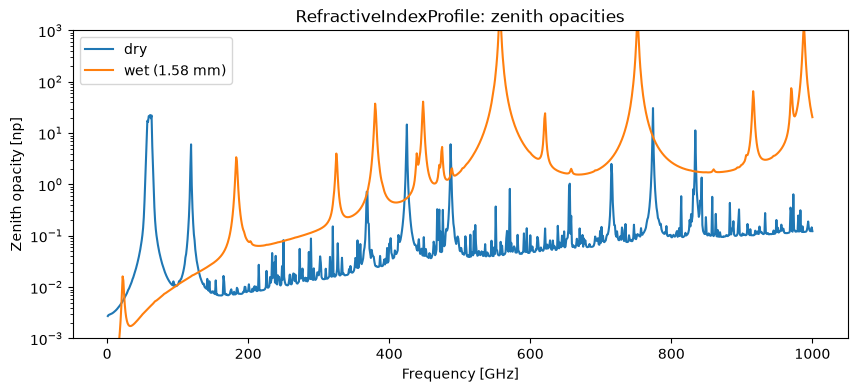

In [5]:
grid = SpectralGrid(1000, 0, Frequency(1, "GHz"), Frequency(1, "GHz"))
rip = RefractiveIndexProfile(grid, profile)
pwv = profile.getGroundWH2O()

freq = np.array([rip.getChanFreq(i).get("GHz") for i in range(rip.getNumChan())])
tau_dry = np.array([rip.getDryOpacity(i).get() for i in range(rip.getNumChan())])
tau_wet = np.array([rip.getWetOpacity(pwv, i).get() for i in range(rip.getNumChan())])

plt.figure(figsize=(10, 4))
plt.semilogy(freq, tau_dry, label="dry")
plt.semilogy(freq, tau_wet, label=f"wet ({pwv.get('mm'):.2f} mm)")
plt.xlabel("Frequency [GHz]"); plt.ylabel("Zenith opacity [np]"); plt.legend(); plt.ylim(1e-3, 1e3)
plt.title("RefractiveIndexProfile: zenith opacities"); plt.show()

## 5. Sky brightness and transmission with `SkyStatus`

`SkyStatus` adds the radiative transfer: equivalent blackbody (`Tebb`) and Rayleigh–Jeans (`Trj`)
sky temperatures, transmission and path lengths for a user water vapour column and air mass.

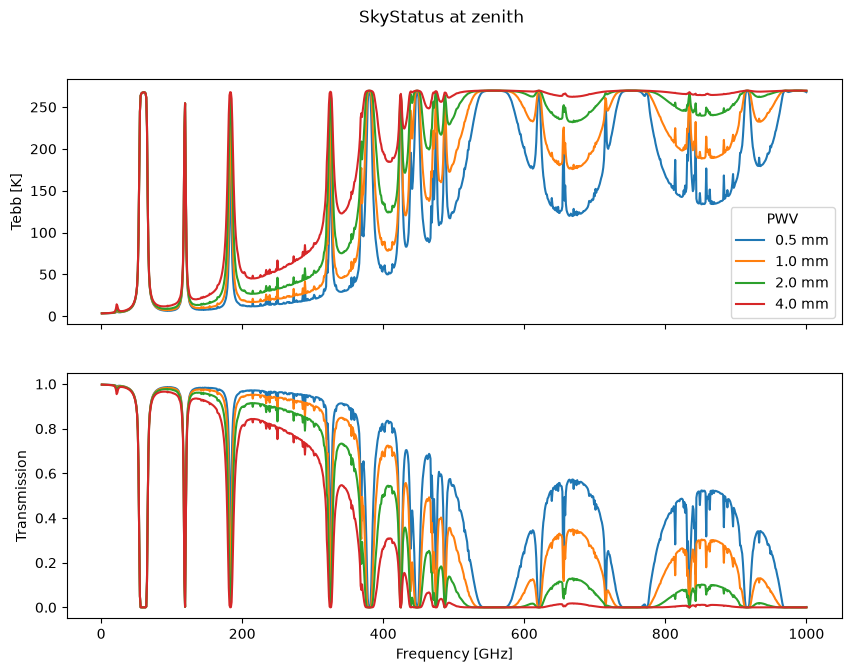

In [6]:
sky = SkyStatus(rip)
sky.setAirMass(1.0)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for w in (0.5, 1.0, 2.0, 4.0):
    sky.setUserWH2O(Length(w, "mm"))
    tebb = np.array([sky.getTebbSky(i).get("K") for i in range(sky.getNumChan())])
    tau = np.array([sky.getWetOpacity(i).get() + sky.getDryOpacity(i).get() for i in range(sky.getNumChan())])
    ax[0].plot(freq, tebb, label=f"{w} mm")
    ax[1].plot(freq, np.exp(-tau * sky.getAirMass()), label=f"{w} mm")
ax[0].set_ylabel("Tebb [K]"); ax[0].legend(title="PWV")
ax[1].set_ylabel("Transmission"); ax[1].set_xlabel("Frequency [GHz]")
fig.suptitle("SkyStatus at zenith"); plt.show()

In [7]:
# Average quantities over a band, and the effect of the air mass (AtmBasicTest / atm651 style)
band = SpectralGrid(64, 32, Frequency(230, "GHz"), Frequency(31.25, "MHz"))
sky230 = SkyStatus(RefractiveIndexProfile(band, profile))
sky230.setUserWH2O(Length(1.0, "mm"))
for el in (90, 60, 30):
    am = 1 / np.sin(np.radians(el))
    sky230.setAirMass(am)
    print(f"el={el:2d} deg  airmass={am:.3f}  Tebb={sky230.getAverageTebbSky().get('K'):7.3f} K  "
          f"Trj={sky230.getAverageTrjSky().get('K'):7.3f} K  "
          f"tau_wet(zenith)={sky230.getAverageWetOpacity(0).get():.4f}  "
          f"wet path={sky230.getAverageNonDispersiveH2OPathLength().get('mm') * am:.3f} mm")

el=90 deg  airmass=1.000  Tebb= 18.524 K  Trj= 13.550 K  tau_wet(zenith)=0.0430  wet path=7.015 mm
el=60 deg  airmass=1.155  Tebb= 20.581 K  Trj= 15.553 K  tau_wet(zenith)=0.0430  wet path=8.100 mm
el=30 deg  airmass=2.000  Tebb= 31.409 K  Trj= 26.213 K  tau_wet(zenith)=0.0430  wet path=14.029 mm


## 6. Water vapour retrieval from a WVR

As in *AbInitioTest*: three double-sideband 183 GHz radiometer channels plus an astronomical band.
A `WaterVaporRadiometer` describes which spectral windows are radiometer channels, their sky coupling,
signal gain and spill-over temperature. Synthetic measurements are generated for a known water column
and the column is then retrieved from them with `WaterVaporRetrieval_fromWVR`.

In [8]:
wvr_ids = []
wvr_grid = RefractiveIndexProfile(SpectralGrid(11, 5, Frequency(182.11, "GHz"), Frequency(0.04, "GHz"),
                                               Frequency(1.20, "GHz"), LSB, DSB), profile)
wvr_ids.append(0)
for ref, sep, if_ in ((179.11, 0.09, 4.2), (175.51, 0.10, 7.8)):
    wvr_ids.append(wvr_grid.getNumSpectralWindow())
    wvr_grid.addNewSpectralWindow(11, 5, Frequency(ref, "GHz"), Frequency(sep, "GHz"), Frequency(if_, "GHz"), LSB, DSB)
wvr_grid.addNewSpectralWindow(31, 15, Frequency(467.75, "GHz"), Frequency(0.05, "GHz"))   # astronomical band
astro = wvr_grid.getNumSpectralWindow() - 1

sky_wvr = SkyStatus(wvr_grid)
coupling, tspill = 0.95, Temperature(275, "K")
sky_wvr.setWaterVaporRadiometer(WaterVaporRadiometer(wvr_ids, [coupling] * 3, [Percent(50, "%")] * 3, tspill))
print("WVR signal spws:", list(sky_wvr.getWaterVaporRadiometer().getIdChannels()))

# Synthetic radiometer data (DSB, 50% signal gain) for a true column of 1.234 mm at 50 deg elevation
true_pwv, elev = Length(1.234, "mm"), Angle(50, "deg")
am = 1 / np.sin(elev.get("rad"))
tsky = [sky_wvr.getAverageTebbSky(i, true_pwv, am, coupling, 0.5, tspill) for i in wvr_ids]
print("Simulated WVR Tsky [K]:", [round(t.get("K"), 3) for t in tsky])

data = [WVRMeasurement(elev, tsky)]
sky_wvr.setUserWH2O(Length(3.0, "mm"))           # first guess
sky_wvr.WaterVaporRetrieval_fromWVR(data, 0, 1)  # the list elements are updated in place
print(f"Retrieved PWV: {sky_wvr.getUserWH2O().get('mm'):.4f} mm (true {true_pwv.get('mm')} mm); "
      f"stored in measurement: {data[0].getretrievedWaterVaporColumn().get('mm'):.4f} mm; "
      f"fit sigma {data[0].getSigmaFit().get('K'):.2e} K")
print(f"Astro band {sky_wvr.getRefFreq(astro).get('GHz')} GHz: "
      f"Tebb={sky_wvr.getAverageTebbSky(astro).get('K'):.3f} K, "
      f"dTebb/dPWV={sky_wvr.getAverageTebbSky(astro, Length(sky_wvr.getUserWH2O().get('mm') + 0.001, 'mm')).get('K') - sky_wvr.getAverageTebbSky(astro).get('K'):.4f} K/micron")

WVR signal spws: [0, 2, 4]
Simulated WVR Tsky [K]: [232.377, 101.82, 55.783]
Retrieved PWV: 1.2340 mm (true 1.234 mm); stored in measurement: 1.2340 mm; fit sigma 6.55e-05 K
Astro band 467.75000000000006 GHz: Tebb=171.447 K, dTebb/dPWV=0.0689 K/micron
